# Punto (e): procesamiento con Dask
## Retrasos de vuelos en EE. UU. (2016–2018)

Se usa Dask en la etapa de **transformación y análisis**: leer los tres CSV originales (2,13 GB, 18,5 millones de vuelos), aplicar las reglas de limpieza del EDA, calcular las tablas de la analítica y guardar los datos limpios en Parquet, como en el ejercicio de clase (`proceso convencional.ipynb`).

El clúster se arma **a mano, como en clase**: el scheduler y los workers se inician en Anaconda Prompt y el notebook se conecta copiando la dirección del scheduler. Se mide **exactamente el mismo trabajo** con:

| Configuración | Comando de los workers | Workers | Hilos por worker | Memoria por worker |
|---|---|---|---|---|
| Pandas (proceso convencional) | — | 1 proceso | 1 | sin límite |
| A | `--nworkers 2 --nthreads 3 --memory-limit 5GB` | 2 | 3 | 5 GB |
| B | `--nworkers 3 --nthreads 2 --memory-limit 3.5GB` | 3 | 2 | 3,5 GB |
| C | `--nworkers 6 --nthreads 1 --memory-limit 1.75GB` | 6 | 1 | 1,75 GB |

Las configuraciones están pensadas para un equipo de 6 núcleos y 16 GB de RAM: los workers suman unos 10 GB y quedan libres unos 5 GB para Windows y VS Code.

**Este notebook se ejecuta celda por celda** (no con *Run All*), porque entre configuraciones hay que cambiar los workers en la terminal. Cada medición se guarda en `salidas_dask/mediciones.json`, así que no se pierde si se reinicia el kernel.

## 0. Instalación (ejecutar solo si Dask no está instalado)

## 1. Librerías y configuración

In [1]:
from pathlib import Path
import json
import os
import shutil
import time
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import psutil
import dask
import dask.dataframe as dd
from dask.distributed import Client

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", palette="pastel")

# Rutas completas: los workers se inician desde otra carpeta (Anaconda Prompt) y necesitan la ruta exacta
DATA_DIR = (Path(".") if any(Path(".").glob("20*.csv")) else Path("Proyecto BD")).resolve()
ARCHIVOS = [DATA_DIR / f"{a}.csv" for a in (2016, 2017, 2018)]
OUT_DIR = Path("salidas_dask").resolve()
OUT_DIR.mkdir(exist_ok=True)
PARQUET_DIR = OUT_DIR / "vuelos_limpios.parquet"
BLOCKSIZE = "64MB"                 # tamaño de cada partición al leer el CSV
EJECUTAR_PANDAS = True             # proceso convencional (línea base). Ponga False si el equipo tiene poca RAM
UMBRAL_RETRASO = 15
PRIMER_GRAFICO, PRIMERA_TABLA = 31, 13   # continúa la numeración del informe

# Dirección del scheduler: copie aquí la que imprime "dask scheduler" en Anaconda Prompt
SCHEDULER = "tcp://127.0.0.1:8786"

# Configuraciones a comparar: letra -> (workers, hilos por worker, memoria por worker)
CONFIGURACIONES = {
    "A": (2, 3, "5GB"),
    "B": (3, 2, "3.5GB"),
    "C": (6, 1, "1.75GB"),
}
MEDICIONES = OUT_DIR / "mediciones.json"

print("Carpeta de datos:", DATA_DIR.resolve())
print(f"Equipo: {psutil.cpu_count(logical=False)} núcleos físicos, {psutil.cpu_count()} procesadores lógicos, "
      f"{psutil.virtual_memory().total / 1024**3:.1f} GB de RAM")
print(f"Dask {dask.__version__} | pandas {pd.__version__}")
print("Archivos:", [f"{a.name} ({a.stat().st_size / 1024**3:.2f} GB)" for a in ARCHIVOS])

Carpeta de datos: C:\Users\USUARIO\Downloads\Proyecto BD
Equipo: 6 núcleos físicos, 12 procesadores lógicos, 15.9 GB de RAM
Dask 2026.8.0 | pandas 3.1.1
Archivos: ['2016.csv (0.65 GB)', '2017.csv (0.65 GB)', '2018.csv (0.83 GB)']


In [2]:
_cont = {"grafico": PRIMER_GRAFICO - 1, "tabla": PRIMERA_TABLA - 1}
def _archivo(prefijo, n, titulo):
    s = unicodedata.normalize("NFKD", titulo.lower()).encode("ascii", "ignore").decode()
    return f"{prefijo}_{n:02d}_" + "".join(c if c.isalnum() else "_" for c in s).strip("_")[:50]
def grafico(fig, titulo):
    _cont["grafico"] += 1; n = _cont["grafico"]
    fig.suptitle(f"Gráfico {n}. {titulo}", fontsize=13, fontweight="bold"); fig.tight_layout()
    fig.savefig(OUT_DIR / f"{_archivo('grafico', n, titulo)}.png", dpi=150, bbox_inches="tight"); plt.show(); plt.close(fig)
def tabla(df, titulo):
    _cont["tabla"] += 1; n = _cont["tabla"]
    print(f"Tabla {n}. {titulo}"); df.to_csv(OUT_DIR / f"{_archivo('tabla', n, titulo)}.csv"); display(df)

## 2. Iniciar el scheduler y los workers (Anaconda Prompt)

Abra **dos ventanas de Anaconda Prompt** y active el entorno en ambas con `conda activate bigdata_env`.

> **Importante en Windows:** no haga clic dentro de estas ventanas mientras Dask trabaja. Un clic activa el modo *Seleccionar* (aparece en el título de la ventana) y **pausa** el scheduler o los workers; el notebook pierde la conexión. Si pasa, pulse **Esc** en esa ventana.

**Ventana 1 – scheduler** (se deja abierta todo el tiempo):
```
dask scheduler
```
Busque la línea `Scheduler at: tcp://...:8786` y copie esa dirección en la variable `SCHEDULER` de la sección 1. El panel de Dask queda en http://localhost:8787.

**Ventana 2 – workers de la configuración A** (reemplace la dirección por la suya):
```
dask worker tcp://127.0.0.1:8786 --nworkers 2 --nthreads 3 --memory-limit 5GB
```

Luego ejecute la celda siguiente para conectar el notebook al clúster.

In [3]:
client = Client(SCHEDULER)

def workers_conectados():
    info = client.scheduler_info()["workers"]
    return pd.DataFrame([{"worker": w["name"], "hilos": w["nthreads"],
                          "memoria (GB)": round(w["memory_limit"] / 1e9, 2)} for w in info.values()])

print("Conectado a", SCHEDULER, "| panel:", client.dashboard_link)
try:
    client.get_versions(check=True)
    print("Versiones de Python, Dask y pandas iguales en el notebook, el scheduler y los workers.")
except Exception as e:
    print("ATENCIÓN: las versiones no coinciden. Cierre las ventanas de Anaconda Prompt, ejecute "
          "'conda activate bigdata_env' en ambas antes de iniciar el scheduler y los workers.\n", str(e)[:600])
workers_conectados()

Conectado a tcp://127.0.0.1:8786 | panel: http://127.0.0.1:8787/status
Versiones de Python, Dask y pandas iguales en el notebook, el scheduler y los workers.


,worker,hilos,memoria (GB)
0,tcp://192.168.20.22:53585,2,3.50
1,tcp://192.168.20.22:53587,2,3.50
2,tcp://192.168.20.22:53588,2,3.50


## 3. Lectura con Dask (como en el ejercicio de clase)

`dd.read_csv` no carga los archivos: crea un plan dividido en **particiones** de 64 MB que los workers procesan en paralelo. Igual que en clase con `ESTADO_FOLIO` y `FOLIOS_DERIVADOS`, se definen los `dtype` de las columnas problemáticas para que Dask no tenga que adivinarlos (aquí, los códigos de cancelación, que son casi todos nulos, y las horas en formato *hhmm*).

In [4]:
CAUSAS = ["CARRIER_DELAY", "WEATHER_DELAY", "NAS_DELAY", "SECURITY_DELAY", "LATE_AIRCRAFT_DELAY"]
DTYPES = {
    "OP_CARRIER": "string", "OP_CARRIER_FL_NUM": "int32", "ORIGIN": "string", "DEST": "string",
    "CRS_DEP_TIME": "int16", "DEP_DELAY": "float32", "TAXI_OUT": "float32", "TAXI_IN": "float32",
    "ARR_DELAY": "float32", "CANCELLED": "float32", "CANCELLATION_CODE": "string", "DIVERTED": "float32",
    "CRS_ELAPSED_TIME": "float32", "ACTUAL_ELAPSED_TIME": "float32", "AIR_TIME": "float32", "DISTANCE": "float32",
    **{c: "float32" for c in CAUSAS},
}
USECOLS = ["FL_DATE", *DTYPES.keys()]

def leer_csv():
    return dd.read_csv([str(a) for a in ARCHIVOS], usecols=USECOLS, dtype=DTYPES,
                       parse_dates=["FL_DATE"], blocksize=BLOCKSIZE)

vuelos_dask = leer_csv()
print(f"Particiones: {vuelos_dask.npartitions}")
vuelos_dask.head()

Particiones: 33


,FL_DATE,OP_CARRIER,OP_CARRIER_FL_NUM,ORIGIN,DEST,CRS_DEP_TIME,DEP_DELAY,TAXI_OUT,TAXI_IN,ARR_DELAY,...,DIVERTED,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,AIR_TIME,DISTANCE,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY
0,2016-01-01,DL,1248,DTW,LAX,1935,0.00,23.00,13.00,-24.00,...,0.00,309.00,285.00,249.00,"1,979.00",NaN,NaN,NaN,NaN,NaN
1,2016-01-01,DL,1251,ATL,GRR,2125,5.00,13.00,4.00,-2.00,...,0.00,116.00,109.00,92.00,640.00,NaN,NaN,NaN,NaN,NaN
2,2016-01-01,DL,1254,LAX,ATL,2255,1.00,19.00,5.00,-13.00,...,0.00,245.00,231.00,207.00,"1,947.00",NaN,NaN,NaN,NaN,NaN
3,2016-01-01,DL,1255,SLC,ATL,1656,4.00,12.00,8.00,-16.00,...,0.00,213.00,193.00,173.00,"1,590.00",NaN,NaN,NaN,NaN,NaN
4,2016-01-01,DL,1256,BZN,MSP,900,72.00,63.00,4.00,124.00,...,0.00,136.00,188.00,121.00,874.00,72.00,0.00,52.00,0.00,0.00


## 4. Transformación (reglas de limpieza del EDA)

Todo queda en el plan de Dask; nada se calcula hasta llamar a `compute()`.

In [5]:
def transformar(ddf):
    ddf = ddf.assign(CANCELLED=ddf["CANCELLED"].fillna(0), DIVERTED=ddf["DIVERTED"].fillna(0))
    operado = (ddf["CANCELLED"] == 0) & (ddf["DIVERTED"] == 0)
    nulos_sin_explicacion = operado & (ddf["DEP_DELAY"].isna() | ddf["ARR_DELAY"].isna() | ddf["AIR_TIME"].isna())
    velocidad = ddf["DISTANCE"] / ddf["AIR_TIME"] * 60
    imposible = ((ddf["AIR_TIME"] <= 0) | (ddf["AIR_TIME"] > ddf["ACTUAL_ELAPSED_TIME"]) | (velocidad > 700)
                 | (velocidad < 100) | (ddf["DEP_DELAY"] < -90) | (ddf["CRS_ELAPSED_TIME"] <= 0)
                 | ((ddf["CRS_DEP_TIME"] % 100) >= 60))
    ddf = ddf[~nulos_sin_explicacion & ~imposible]

    operado = (ddf["CANCELLED"] == 0) & (ddf["DIVERTED"] == 0)
    sin_causa = operado & (ddf["ARR_DELAY"] < UMBRAL_RETRASO)
    ddf = ddf.assign(**{c: ddf[c].mask(sin_causa & ddf[c].isna(), 0) for c in CAUSAS})
    return ddf.assign(
        OPERADO=operado.astype("int8"),
        RETRASADO=(ddf["ARR_DELAY"] >= UMBRAL_RETRASO).astype("float32").where(operado),
        ANIO=ddf["FL_DATE"].dt.year.astype("int16"),
        MES=ddf["FL_DATE"].dt.month.astype("int8"),
        DIA_SEMANA=ddf["FL_DATE"].dt.weekday.astype("int8"),
        HORA_SALIDA=((ddf["CRS_DEP_TIME"] // 100) % 24).astype("int8"),
    )

vuelos_limpios = transformar(vuelos_dask)
print("Columnas después de la transformación:", list(vuelos_limpios.columns))

Columnas después de la transformación: ['FL_DATE', 'OP_CARRIER', 'OP_CARRIER_FL_NUM', 'ORIGIN', 'DEST', 'CRS_DEP_TIME', 'DEP_DELAY', 'TAXI_OUT', 'TAXI_IN', 'ARR_DELAY', 'CANCELLED', 'CANCELLATION_CODE', 'DIVERTED', 'CRS_ELAPSED_TIME', 'ACTUAL_ELAPSED_TIME', 'AIR_TIME', 'DISTANCE', 'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY', 'OPERADO', 'RETRASADO', 'ANIO', 'MES', 'DIA_SEMANA', 'HORA_SALIDA']


## 5. Analítica

Las mismas tablas que usa el informe. Se piden todas juntas con un solo `dask.compute`, para que Dask lea cada partición una vez y comparta el trabajo.

In [6]:
def analitica(ddf):
    operados = ddf[ddf["OPERADO"] == 1]
    tareas = {
        "vuelos": ddf["OPERADO"].count(),
        "operados": ddf["OPERADO"].sum(),
        "retrasados": ddf["RETRASADO"].sum(),
        "cancelados": ddf["CANCELLED"].sum(),
        "por_anio": ddf.groupby("ANIO").agg({"OPERADO": "sum", "RETRASADO": "sum", "CANCELLED": "sum"}),
        "por_mes": operados.groupby(["ANIO", "MES"])["RETRASADO"].mean(),
        "por_hora": operados.groupby("HORA_SALIDA")["RETRASADO"].mean(),
        "por_aerolinea": operados.groupby("OP_CARRIER")["RETRASADO"].agg(["mean", "count"]),
        "por_aeropuerto": operados.groupby("ORIGIN")["RETRASADO"].agg(["mean", "count"]),
        "minutos_causa": operados[CAUSAS].sum(),
    }
    nombres = list(tareas)
    valores = dask.compute(*tareas.values())
    return dict(zip(nombres, valores))

def resumen(r):
    return {"vuelos": int(r["vuelos"]), "tasa_retraso": round(float(r["retrasados"] / r["operados"] * 100), 2),
            "tasa_cancelacion": round(float(r["cancelados"] / r["vuelos"] * 100), 2)}

## 6. Línea base: proceso convencional con pandas

Un solo proceso lee los tres archivos completos en memoria y hace las mismas operaciones, sin usar los workers. Es el punto de comparación para Dask.

In [8]:
def guardar_medicion(m):
    datos = json.loads(MEDICIONES.read_text(encoding="utf-8")) if MEDICIONES.exists() else {}
    datos[m["Configuración"]] = m
    MEDICIONES.write_text(json.dumps(datos, ensure_ascii=False, indent=2), encoding="utf-8")

if EJECUTAR_PANDAS:
    with dask.config.set(scheduler="synchronous"):      # sin paralelismo: equivale a pandas puro
        t0 = time.perf_counter()
        pdf = pd.concat([pd.read_csv(a, usecols=USECOLS, dtype=DTYPES, parse_dates=["FL_DATE"]) for a in ARCHIVOS],
                        ignore_index=True)
        t_lectura = time.perf_counter() - t0
        res_pandas = analitica(transformar(dd.from_pandas(pdf, npartitions=1)))
        t_total = time.perf_counter() - t0
    memoria_pandas = pdf.memory_usage(deep=True).sum() / 1024**3
    del pdf
    guardar_medicion({"Configuración": "Pandas (convencional)", "Workers": 1, "Hilos por worker": 1,
                      "Memoria por worker (GB)": None, "Segundos": round(t_total, 1), **resumen(res_pandas)})
    print(f"Pandas: {t_total:,.1f} s (lectura {t_lectura:,.1f} s) | DataFrame en memoria: {memoria_pandas:.2f} GB")
    print(resumen(res_pandas))

Pandas: 28.1 s (lectura 16.1 s) | DataFrame en memoria: 1.97 GB
{'vuelos': 18498075, 'tasa_retraso': 18.39, 'tasa_cancelacion': 1.43}


## 7. Medir cada configuración

La función `medir_configuracion` revisa que los workers conectados correspondan a la configuración indicada, ejecuta el trabajo completo (leer los CSV, transformar y calcular la analítica) y guarda el tiempo. Deje abierto el panel de Dask (http://localhost:8787) **antes** de ejecutar cada celda y tome una captura mientras corre: el *Task Stream* muestra en vivo el trabajo de cada worker.

In [9]:
resultados = {}

def medir_configuracion(letra):
    n_workers, hilos, memoria = CONFIGURACIONES[letra]
    w = workers_conectados()
    mem_gb = dask.utils.parse_bytes(memoria) / 1e9        # Dask usa GB decimales: "5GB" = 5e9 bytes
    if (len(w) != n_workers or not (w["hilos"] == hilos).all()
            or not np.isclose(w["memoria (GB)"], mem_gb, rtol=0.02).all()):
        print(f"Los workers conectados ({len(w)} workers, hilos {sorted(w['hilos'].unique())}, "
              f"memoria {sorted(w['memoria (GB)'].unique())} GB) no corresponden a la configuración {letra}.")
        print(f"En la ventana 2 detenga los workers con Ctrl + C y ejecute:\n"
              f"  dask worker {SCHEDULER} --nworkers {n_workers} --nthreads {hilos} --memory-limit {memoria}\n"
              f"Espere unos segundos y vuelva a ejecutar esta celda.")
        return None
    nombre = f"Dask {letra}: {n_workers} workers x {hilos} {'hilo' if hilos == 1 else 'hilos'}, {memoria}"
    t0 = time.perf_counter()
    r = analitica(transformar(leer_csv()))
    seg = time.perf_counter() - t0
    resultados[letra] = r
    guardar_medicion({"Configuración": nombre, "Workers": n_workers, "Hilos por worker": hilos,
                      "Memoria por worker (GB)": mem_gb, "Segundos": round(seg, 1), **resumen(r)})
    print(f"{nombre}: {seg:,.1f} s | {resumen(r)}")
    return r

### Configuración A: 2 workers × 3 hilos, 5 GB

Workers iniciados en la ventana 2 con `--nworkers 2 --nthreads 3 --memory-limit 5GB`. Tome una captura de las dos ventanas de Anaconda Prompt y del panel de Dask mientras corre.

In [12]:
display(workers_conectados())
r_A = medir_configuracion("A")

,worker,hilos,memoria (GB)
0,tcp://192.168.20.22:54155,3,5.00
1,tcp://192.168.20.22:54157,3,5.00


Dask A: 2 workers x 3 hilos, 5GB: 14.2 s | {'vuelos': 18498075, 'tasa_retraso': 18.39, 'tasa_cancelacion': 1.43}


### Configuración B: 3 workers × 2 hilos, 3,5 GB

En la ventana 2 detenga los workers con **Ctrl + C** y ejecute:
```
dask worker tcp://127.0.0.1:8786 --nworkers 3 --nthreads 2 --memory-limit 3.5GB
```
Espere unos segundos a que se conecten y ejecute la celda.

In [10]:
display(workers_conectados())
r_B = medir_configuracion("B")

,worker,hilos,memoria (GB)
0,tcp://192.168.20.22:53585,2,3.50
1,tcp://192.168.20.22:53587,2,3.50
2,tcp://192.168.20.22:53588,2,3.50


Dask B: 3 workers x 2 hilos, 3.5GB: 15.1 s | {'vuelos': 18498075, 'tasa_retraso': 18.39, 'tasa_cancelacion': 1.43}


### Configuración C: 6 workers × 1 hilo, 1,75 GB

En la ventana 2 detenga los workers con **Ctrl + C** y ejecute:
```
dask worker tcp://127.0.0.1:8786 --nworkers 6 --nthreads 1 --memory-limit 1.75GB
```
Espere unos segundos a que se conecten y ejecute la celda.

In [11]:
display(workers_conectados())
r_C = medir_configuracion("C")

,worker,hilos,memoria (GB)
0,tcp://192.168.20.22:54036,1,1.75
1,tcp://192.168.20.22:54037,1,1.75
2,tcp://192.168.20.22:54038,1,1.75
3,tcp://192.168.20.22:54039,1,1.75
4,tcp://192.168.20.22:54044,1,1.75
5,tcp://192.168.20.22:54046,1,1.75


Dask C: 6 workers x 1 hilo, 1.75GB: 11.8 s | {'vuelos': 18498075, 'tasa_retraso': 18.39, 'tasa_cancelacion': 1.43}


## 8. Comparación de tiempos

Tabla 13. Tiempo del mismo trabajo con cada configuración


,Workers,Hilos por worker,Memoria por worker (GB),Segundos,Veces más rápido que la primera fila
Configuración,,,,,
Pandas (convencional),1,1,NaN,28.10,1.00
"Dask A: 2 workers x 3 hilos, 5GB",2,3,5.00,14.20,1.98
"Dask B: 3 workers x 2 hilos, 3.5GB",3,2,3.50,15.10,1.86
"Dask C: 6 workers x 1 hilo, 1.75GB",6,1,1.75,11.80,2.38


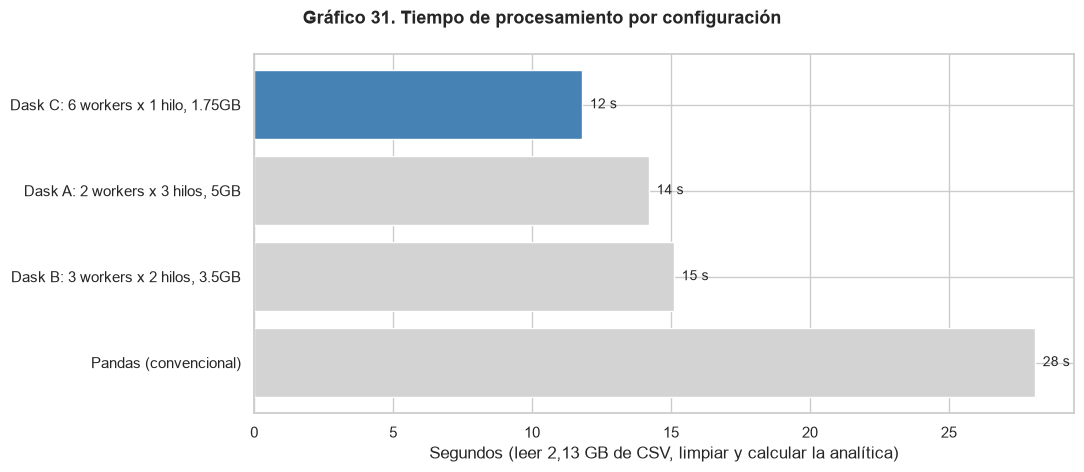

Configuración más rápida: Dask C: 6 workers x 1 hilo, 1.75GB (11.8 s).
Mejor configuración de Dask: Dask C: 6 workers x 1 hilo, 1.75GB (11.8 s).


In [13]:
mediciones = json.loads(MEDICIONES.read_text(encoding="utf-8"))
t = pd.DataFrame(mediciones.values()).set_index("Configuración")
t = t.loc[sorted(t.index, key=lambda i: (not i.startswith("Pandas"), i))]
base = t["Segundos"].iloc[0]
t["Veces más rápido que la primera fila"] = (base / t["Segundos"]).round(2)
tabla(t[["Workers", "Hilos por worker", "Memoria por worker (GB)", "Segundos", "Veces más rápido que la primera fila"]],
      "Tiempo del mismo trabajo con cada configuración")

fig, ax = plt.subplots(figsize=(11, 4.8))
orden = t.sort_values("Segundos")
colores = ["steelblue" if i == orden["Segundos"].idxmin() else "lightgray" for i in orden.index]
ax.barh(orden.index, orden["Segundos"], color=colores)
for y, v in enumerate(orden["Segundos"]):
    ax.text(v + base * 0.01, y, f"{v:,.0f} s", va="center", fontsize=10)
ax.set(xlabel="Segundos (leer 2,13 GB de CSV, limpiar y calcular la analítica)", ylabel="")
ax.invert_yaxis()
grafico(fig, "Tiempo de procesamiento por configuración")

solo_dask = t[t.index.str.startswith("Dask ")]
if solo_dask.empty:
    raise RuntimeError("Todavía no hay mediciones de Dask: ejecute las celdas de las configuraciones A, B y C (sección 7).")
mejor = t["Segundos"].idxmin()
mejor_dask = solo_dask["Segundos"].idxmin()
print(f"Configuración más rápida: {mejor} ({t.loc[mejor, 'Segundos']:,.1f} s).")
print(f"Mejor configuración de Dask: {mejor_dask} ({t.loc[mejor_dask, 'Segundos']:,.1f} s).")

In [14]:
# Verificación: todas las configuraciones deben dar exactamente el mismo resultado
verif = t[["vuelos", "tasa_retraso", "tasa_cancelacion"]]
tabla(verif, "Mismos resultados con todas las configuraciones")
print("Resultados idénticos:", verif.nunique().eq(1).all())

Tabla 14. Mismos resultados con todas las configuraciones


,vuelos,tasa_retraso,tasa_cancelacion
Configuración,,,
Pandas (convencional),18498075,18.39,1.43
"Dask A: 2 workers x 3 hilos, 5GB",18498075,18.39,1.43
"Dask B: 3 workers x 2 hilos, 3.5GB",18498075,18.39,1.43
"Dask C: 6 workers x 1 hilo, 1.75GB",18498075,18.39,1.43


Resultados idénticos: True


## 9. Guardar los datos limpios en Parquet (como en clase)

Con los workers que estén conectados (al terminar la sección 7 son los de la configuración C) se escriben los vuelos limpios en Parquet comprimido (`snappy`), particionado por año. Luego se repite la analítica leyendo el Parquet en lugar de los CSV, para medir la ganancia con la misma configuración.

Tabla 15. CSV frente a Parquet con la configuración 2 workers x 3 hilos, 5.0 GB (los que están conectados)


,Tamaño en disco (GB),Segundos de la analítica
CSV originales,2.13,14.20
Parquet limpio (snappy),0.29,3.38


Escritura del Parquet: 12.7 s | resultado leyendo Parquet: {'vuelos': 18498075, 'tasa_retraso': 18.39, 'tasa_cancelacion': 1.43}


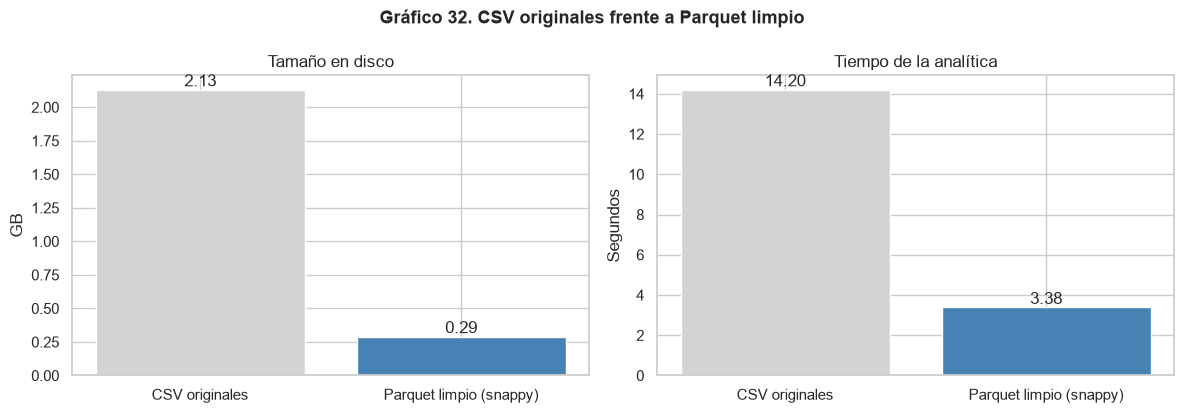

In [15]:
w = workers_conectados()
nombre = f"{len(w)} workers x {w['hilos'].iloc[0]} hilos, {w['memoria (GB)'].iloc[0]} GB (los que están conectados)"
fila_actual = [i for i in t.index if i.startswith("Dask") and f"{len(w)} workers x {w['hilos'].iloc[0]} hilo" in i]
if PARQUET_DIR.exists():
    shutil.rmtree(PARQUET_DIR)

if True:
    t0 = time.perf_counter()
    transformar(leer_csv()).to_parquet(PARQUET_DIR, engine="pyarrow", compression="snappy",
                                       partition_on=["ANIO"], write_index=False)
    t_escritura = time.perf_counter() - t0

    t0 = time.perf_counter()
    r_parquet = analitica(dd.read_parquet(PARQUET_DIR, engine="pyarrow"))
    t_parquet = time.perf_counter() - t0

tam_csv = sum(a.stat().st_size for a in ARCHIVOS) / 1024**3
tam_parquet = sum(p.stat().st_size for p in PARQUET_DIR.rglob("*.parquet")) / 1024**3
t_csv = t.loc[fila_actual[0], "Segundos"] if fila_actual else t.loc[mejor_dask, "Segundos"]
formato = pd.DataFrame({
    "Tamaño en disco (GB)": [tam_csv, tam_parquet],
    "Segundos de la analítica": [t_csv, t_parquet],
}, index=["CSV originales", "Parquet limpio (snappy)"]).round(2)
tabla(formato, f"CSV frente a Parquet con la configuración {nombre}")
print(f"Escritura del Parquet: {t_escritura:,.1f} s | resultado leyendo Parquet: {resumen(r_parquet)}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].bar(formato.index, formato["Tamaño en disco (GB)"], color=["lightgray", "steelblue"])
ax[0].set(ylabel="GB", title="Tamaño en disco")
ax[1].bar(formato.index, formato["Segundos de la analítica"], color=["lightgray", "steelblue"])
ax[1].set(ylabel="Segundos", title="Tiempo de la analítica")
for a, col in zip(ax, formato.columns):
    for i, v in enumerate(formato[col]):
        a.text(i, v, f"{v:,.2f}", ha="center", va="bottom")
grafico(fig, "CSV originales frente a Parquet limpio")

## 10. Resultados de la analítica calculados con Dask

Tabla 16. Tasa de retraso por año calculada con Dask


,% retraso,vuelos operados
ANIO,,
2016,17.41,5538021
2017,18.45,5579288
2018,19.12,7071606


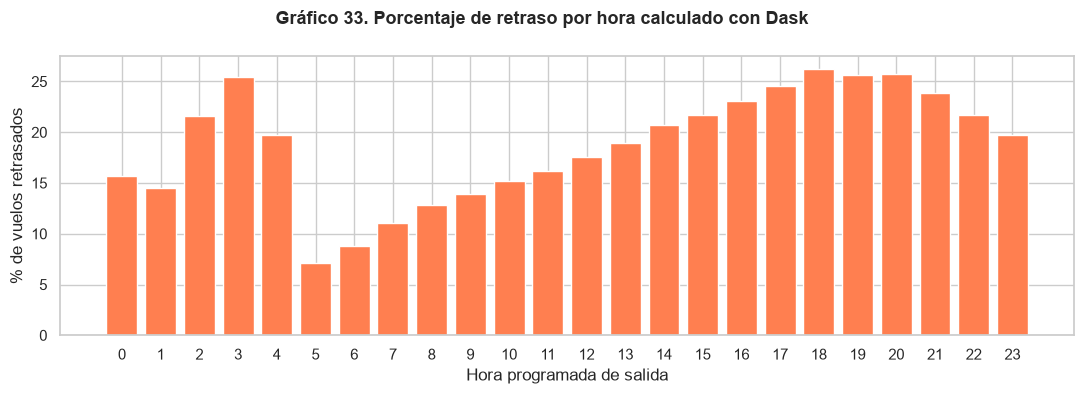

{
  "configuraciones": [
    {
      "Configuración": "Pandas (convencional)",
      "Workers": 1,
      "Hilos por worker": 1,
      "Memoria por worker (GB)": null,
      "Segundos": 28.1,
      "vuelos": 18498075,
      "tasa_retraso": 18.39,
      "tasa_cancelacion": 1.43
    },
    {
      "Configuración": "Dask B: 3 workers x 2 hilos, 3.5GB",
      "Workers": 3,
      "Hilos por worker": 2,
      "Memoria por worker (GB)": 3.5,
      "Segundos": 15.1,
      "vuelos": 18498075,
      "tasa_retraso": 18.39,
      "tasa_cancelacion": 1.43
    },
    {
      "Configuración": "Dask C: 6 workers x 1 hilo, 1.75GB",
      "Workers": 6,
      "Hilos por worker": 1,
      "Memoria por worker (GB)": 1.75,
      "Segundos": 11.8,
      "vuelos": 18498075,
      "tasa_retraso": 18.39,
      "tasa_cancelacion": 1.43
    },
    {
      "Configuración": "Dask A: 2 workers x 3 hilos, 5GB",
      "Workers": 2,
      "Hilos por worker": 3,
      "Memoria por worker (GB)": 5.0,
      "Segundos": 14.

In [16]:
r = r_parquet                  # mismos datos limpios, leídos desde Parquet
pa = r["por_anio"]
anual = pd.DataFrame({"% retraso": pa["RETRASADO"] / pa["OPERADO"] * 100,
                      "vuelos operados": pa["OPERADO"]}).sort_index()
tabla(anual.round(2), "Tasa de retraso por año calculada con Dask")

hora = (r["por_hora"] * 100).sort_index()
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(hora.index, hora.values, color="coral")
ax.set(xlabel="Hora programada de salida", ylabel="% de vuelos retrasados", xticks=range(24))
grafico(fig, "Porcentaje de retraso por hora calculado con Dask")

resumen_final = {"configuraciones": list(mediciones.values()), "mas_rapida": mejor, "mejor_dask": mejor_dask,
                 "resultado": resumen(r),
                 "parquet": {"gb_csv": round(tam_csv, 2), "gb_parquet": round(tam_parquet, 2),
                             "seg_csv": t_csv, "seg_parquet": round(t_parquet, 1), "seg_escritura": round(t_escritura, 1)}}
(OUT_DIR / "resumen_dask.json").write_text(json.dumps(resumen_final, ensure_ascii=False, indent=2, default=str),
                                           encoding="utf-8")
print(json.dumps(resumen_final, ensure_ascii=False, indent=2, default=str))

## 11. Qué observar para el informe

- **Pandas frente a Dask:** pandas carga todo en un solo proceso y en memoria; Dask reparte las particiones entre los workers.
- **Más workers no siempre es más rápido:** con 6 workers de 1 hilo hay más paralelismo, pero cada worker tiene menos memoria y hay más comunicación entre procesos. La tabla de tiempos muestra cuál equilibrio funciona mejor en este equipo.
- **Memoria por worker:** si un worker se acerca a su límite, Dask pasa datos a disco (*spill*) y se vuelve más lento. En el panel de Dask, la pestaña *Workers* muestra la memoria de cada uno.
- **Parquet:** leer los datos ya limpios en formato columnar y comprimido es mucho más rápido que volver a leer y limpiar los CSV.

## 12. Cerrar el clúster

Desconecte el notebook y, en las ventanas de Anaconda Prompt, detenga los workers y el scheduler con **Ctrl + C**.

In [17]:
client.close()
print("Notebook desconectado del scheduler.")

Notebook desconectado del scheduler.
